# Training Metrics Visualization

Comparison of dual-stream checkpoints vs the reference base model (separator: pythia-160m). Metrics are computed **against the base model's prediction**; step 0 corresponds to the untrained baseline (no finetuning).


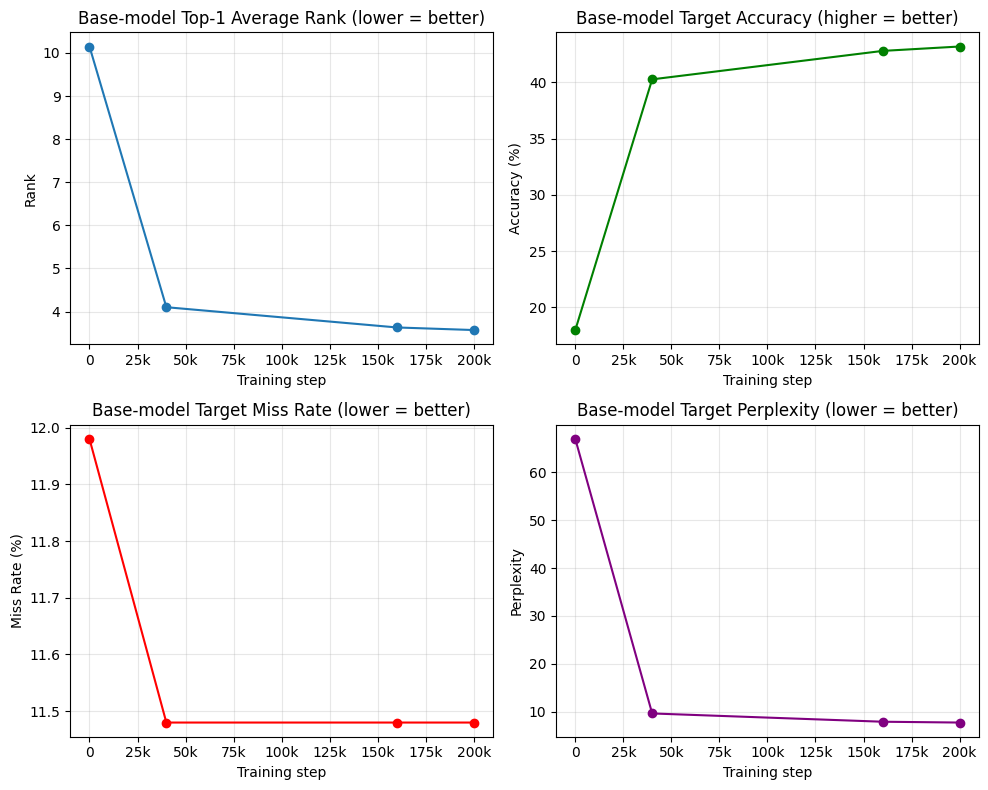

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Steps (0 = untrained baseline)
steps = [0, 40_000, 160_000, 200_000]

# Metrics against the base model (Top-1) using separator pythia-160m
base_top1_rank = [10.15, 4.10, 3.63, 3.57]
base_target_accuracy = [17.98, 40.27, 42.80, 43.19]  # %
base_target_miss_rate = [11.98, 11.48, 11.48, 11.48]  # %
# Averaged perplexity over text A/B (on non-missed base targets)
base_target_perplexity = [66.96, 9.63, 7.90, 7.73]

# Formatter for x-axis ticks: 0, 40k, 160k, 200k
def _k_formatter(x, pos):
    if x >= 1000:
        return f"{int(x/1000)}k"
    return str(int(x))
x_formatter = FuncFormatter(_k_formatter)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

# Base-model Top-1 Rank (lower is better)
axes[0].plot(steps, base_top1_rank, marker='o')
axes[0].set_title('Base-model Top-1 Average Rank (lower = better)')
axes[0].set_xlabel('Training step')
axes[0].set_ylabel('Rank')
axes[0].grid(True, alpha=0.3)

# Base-model Target Accuracy (higher is better)
axes[1].plot(steps, base_target_accuracy, marker='o', color='green')
axes[1].set_title('Base-model Target Accuracy (higher = better)')
axes[1].set_xlabel('Training step')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True, alpha=0.3)

# Base-model Target Miss Rate (lower is better)
axes[2].plot(steps, base_target_miss_rate, marker='o', color='red')
axes[2].set_title('Base-model Target Miss Rate (lower = better)')
axes[2].set_xlabel('Training step')
axes[2].set_ylabel('Miss Rate (%)')
axes[2].grid(True, alpha=0.3)

# Base-model Target Perplexity (lower is better)
axes[3].plot(steps, base_target_perplexity, marker='o', color='purple')
axes[3].set_title('Perplexity (lower = better)')
# axes[3].set_title('Base-model Target Perplexity (lower = better)')
axes[3].set_xlabel('Training step')
axes[3].set_ylabel('Perplexity')
axes[3].grid(True, alpha=0.3)

# Apply formatter to all x-axes
for ax in axes:
    ax.xaxis.set_major_formatter(x_formatter)

plt.tight_layout()
plt.show()

